In [3]:
import os
import pandas as pd
from docx import Document

# Dir_instruct = os.path.join(Dir_working,'instructions')

In [21]:
def parse_segmentation(Dir_segments,file):
    filepath = os.path.join(Dir_segments,file)
    story = file.split('_')[2].split('.')[0]

    file_output = os.path.join(Dir_segments,f'segment_{story}_formatted.csv')
    if os.path.exists(file_output):
        df_segment = pd.read_csv(file_output)
        return(df_segment)
    
    doc = Document(filepath)
    lines = []
    for paragraph in doc.paragraphs:
        line = paragraph.text.strip()
        if line:  # Ignore empty lines
            line = line.replace('—','-').replace('–','-')
            line = line.replace("…","...")
            line = line.replace('‘',"'").replace('“','"').replace('’',"'").replace('”','"')
            lines.append(line)
    
    df = pd.DataFrame({'segment':lines})
    df['flag'] = 'reason'
    df.loc[(df['segment'].str.startswith('[')),'flag'] = 'segment'
    # df.loc[(df['segment'].str.startswith('[')) &( df['segment'].str.endswith(']')),'flag'] = 'segment'
    if not df.loc[0,'segment'].startswith('['):
        df.loc[0,'flag'] = 'title'

    df_segment = []
    List_idx = df.loc[df['flag']=='segment'].index
    for i,idx in enumerate(List_idx):
        text = df.loc[idx,'segment'][1:-1]

        if idx != List_idx[-1]:
            List_idx_reason = list(range(idx+1,List_idx[i+1]))
        else:
            List_idx_reason = list(range(idx+1,df.shape[0]))

        if not List_idx_reason:
            reason = '-'
        else:
            reason = '; '.join(df.loc[List_idx_reason,'segment'].values)

        df_segment.append(pd.DataFrame({'segment':text,'reason':reason},index=[0]))

    if not df_segment:
        print(f'Format error: {story}')
        return(df_segment)             
    df_segment = pd.concat(df_segment,ignore_index=True)
    df_segment['story'] = story
    df_segment['idx'] = df_segment.index
    df_segment['segment'] = df_segment['segment'].str.replace('’',"'")
    df_segment['segment'] = df_segment['segment'].str.replace('‘',"'")
    df_segment['segment'] = df_segment['segment'].str.replace('“','"')
    df_segment['segment'] = df_segment['segment'].str.replace('”','"')
    
    df_segment.to_csv(file_output,index=False)
    return(df_segment)



In [22]:
Dir_github = r'X:\PROJECTS\ABC@UofSC\3-Experiments\NSF_valence\github'
repo = 'ABC_valence'
# pipeline = 'segmentation_Anyssa'
# Dir_working = os.path.join(Dir_github,repo,pipeline)
Dir_segments = os.path.join(Dir_github,'derivatives','behavioral','segmentation')

List_files = [x for x in os.listdir(Dir_segments) if '.docx' in x]
# List_files
dfs_segment = []
for file in List_files:
    df_segment = parse_segmentation(Dir_segments,file)
    if len(df_segment)>0:
        dfs_segment.append(df_segment)
dfs_segment = pd.concat(dfs_segment,ignore_index=True)
dfs_segment

,segment,reason,story,idx
0,"Long, long ago",positioning element,AgedMother,0
1,there lived at the foot of the mountain,positioning element,AgedMother,1
2,"a poor farmer and his aged, widowed mother.",>maximal segment,AgedMother,2
3,They owned a bit of land,-,AgedMother,3
4,"which supplied them with food,",relative clause,AgedMother,4
...,...,...,...,...
2995,"to help us in everyday life,",infinitival phrase,UserFriendly,133
2996,"to carry our packages, provide a way to sit wh...",infinitival phrase,UserFriendly,134
2997,"and yes, to maintain our balance?",conjunction; >maximal segment,UserFriendly,135
2998,"Make them items of pride, stylish enough",-,UserFriendly,136


In [20]:
file

'checked_segment_AgedMother.docx'

# Summary

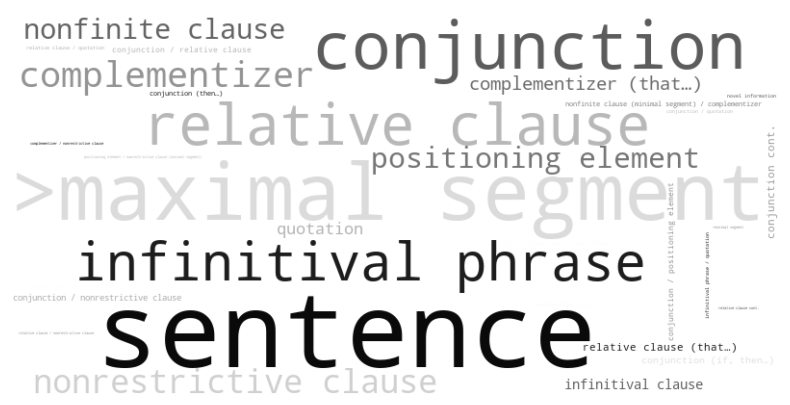

,reason_main,segment,reason,story,idx
66,sentence,823,823,823,823
0,>maximal segment,485,485,485,485
12,conjunction,324,324,324,324
56,relative clause,241,241,241,241
30,infinitival phrase,211,211,211,211
3,complementizer,178,178,178,178
43,nonrestrictive clause,173,173,173,173
49,positioning element,166,166,166,166
39,nonfinite clause,153,153,153,153
5,complementizer (that…),44,44,44,44


In [62]:
import pandas as pd
from wordcloud import WordCloud
import matplotlib.pyplot as plt

# Example DataFrame
df_plot = dfs_segment.copy()
df_plot.loc[df_plot['reason']=='-','reason'] = 'sentence'
df_plot['reason_main'] = df_plot['reason'].str.split('; ',expand=True)[0]
df_plot = df_plot.groupby('reason_main').count().reset_index().sort_values('segment',ascending=False)
df_plot = df_plot.loc[df_plot['segment']>=2]

# Create a dictionary from the DataFrame
word_freq = dict(zip(df_plot['reason_main'], df_plot['segment']))

# Generate the word cloud
wordcloud = WordCloud(width=800, height=400, background_color='white',colormap='Grays').generate_from_frequencies(word_freq)

# Display the word cloud
plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.show()
df_plot

In [63]:
df_Nseg = dfs_segment[['story','segment']].groupby(['story']).count().reset_index()
Nseg_mean = df_Nseg['segment'].mean().round(2)
Nseg_std = round(df_Nseg['segment'].std(),2)
print(f"On average, a story has {Nseg_mean} (SD = {Nseg_std}) segments")
df_Nseg

On average, a story has 130.43 (SD = 21.77) segments


,story,segment
0,AgedMother,128
1,Aqua,147
2,BiggestWastes,152
3,BradfordBoar,157
4,BulliesPronoun,158
5,BulliesRepeatedNames,148
6,Elvis,157
7,EmotionSentences,84
8,EmpireState,113
9,FairyTree,110
